# Alerts Pipeline — End-to-End QC

Runs all five pipeline stages (detect → score → facts → investigate) with inspection cells between each stage.

| Cell | Stage | What happens |
|------|-------|--------------|
| 1 | Config | Set analysis date, optional store filter, composite score weights |
| 2 | Session | Connect to Snowflake, load typed config |
| 3 | Data load — OSA | OSA + hierarchy joined, feedback cached |
| 4 | Data load — WMD | Markdown log, sales, wastage, item/store hierarchy |
| 5–6 | **Stage 1 — Detect** | Run all detectors, inspect anomalies by signal type |
| 7–9 | **Stage 2 — Score** | Score signals, inspect composite dimension breakdown |
| 10–11 | **Stage 3 — Facts** | Enrich signals, inspect facts per signal type |
| 12–13 | **Stage 4 — Investigate** | Generate narratives, inspect per signal type |
| 14 | Full card preview | Read one complete alert card per signal type |

In [1]:
# ── Date window ────────────────────────────────────────────────────────────────
# Set ANALYSIS_DATE_STR to the last day of the week you want to analyse.
ANALYSIS_DATE_STR = '2026-03-20'

# ── Client config (None = base defaults; 'eastofengland' = client override) ────
CLIENT = None

# ── Optional: restrict to one store for a faster test run ─────────────────────
QC_STORE_ID = None   # e.g. 507 — set to None for all stores

# ── Fact-gathering parameters ─────────────────────────────────────────────────
PROJECTION_WEEKS = 4      # cost-if-not-fixed projection horizon
DRILLDOWN_TOP_N  = 3      # top-N PPGs in drilldown lists

# ── Composite score config for QC ─────────────────────────────────────────────
# Leave COMPOSITE_WEIGHTS empty ({}) to use raw projected_cost scoring.
# Populate to see composite dimension breakdown in Stage 2 cells.
COMPOSITE_WEIGHTS = {
    'financial_severity':      0.50,
    'vs_control_benchmark':    0.25,
    'vs_historical_benchmark': 0.10,
    'thematic':                0.05,
    'historical_recency':      0.05,
    'special_cases':           0.05,
}
COST_CEILINGS = {
    'OSA':                  5000.0,
    'COMPLIANCE':           5000.0,
    'WASTE':                2000.0,
    'MARKDOWN_OVERRIDE':    2000.0,
    'MARKDOWN_SELLTHROUGH': 2000.0,
    'MARKDOWN_SKU':         1000.0,
}
BENCHMARK_CEILINGS = {
    'OSA': 10,                 
    'COMPLIANCE': 10,
    'WASTE': 15,               
    'MARKDOWN_OVERRIDE': 15,
    'MARKDOWN_SELLTHROUGH': 15,
}
WOW_CEILINGS = {
    'OSA': 10, 'COMPLIANCE': 10, 'WASTE': 15,
    'MARKDOWN_OVERRIDE': 15, 'MARKDOWN_SELLTHROUGH': 15,
}

import datetime

analysis_date   = datetime.date.fromisoformat(ANALYSIS_DATE_STR)
THIS_WEEK_END   = str(analysis_date)
THIS_WEEK_START = str(analysis_date - datetime.timedelta(days=6))
LAST_WEEK_END   = str(analysis_date - datetime.timedelta(days=7))
LAST_WEEK_START = str(analysis_date - datetime.timedelta(days=13))
LOOKBACK_START  = str(analysis_date - datetime.timedelta(days=69))  # ~10 weeks
WMD_LOOKBACK    = str(analysis_date - datetime.timedelta(days=27))  # 4 weeks for SKU detectors

print(f'Analysis date : {THIS_WEEK_END}')
print(f'This week     : {THIS_WEEK_START} – {THIS_WEEK_END}')
print(f'Last week     : {LAST_WEEK_START} – {LAST_WEEK_END}')
print(f'Lookback      : {LOOKBACK_START} – {THIS_WEEK_END}')
print(f'WMD window    : {WMD_LOOKBACK} – {THIS_WEEK_END}')
print(f'Client        : {CLIENT or "base defaults"}')
print(f'Store filter  : {QC_STORE_ID or "all stores"}')
print(f'Composite     : {"enabled" if COMPOSITE_WEIGHTS else "disabled (raw projected_cost)"}')

Analysis date : 2026-03-20
This week     : 2026-03-14 – 2026-03-20
Last week     : 2026-03-07 – 2026-03-13
Lookback      : 2026-01-10 – 2026-03-20
WMD window    : 2026-02-21 – 2026-03-20
Client        : base defaults
Store filter  : all stores
Composite     : enabled


In [2]:
import sys, os, logging, warnings

_root = os.path.abspath(os.path.join('..', '..', '..'))
if _root not in sys.path:
    sys.path.insert(0, _root)

logging.getLogger('snowflake.connector').setLevel(logging.ERROR)
logging.getLogger('snowflake.snowpark').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=UserWarning, module='snowflake')

from store_insight.pipeline.config.loader import load_config
from store_insight.pipeline.pipeline.session import create_session

cfg = load_config(CLIENT)
print(f'Config loaded: client={cfg.client_name}')

Config loaded: client=default


In [3]:
session = create_session(cfg)

 pip install snowflake-connector-python[secure-local-storage]


Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...
Going to open: https://login.microsoftonline.com/93a31d5d-1a5d-433f-baa0-138549cd2108/saml2?SAMLRequest=nZJdb9owFIb%2FSuRdx3E%2BqMACKgbrRkcpgtBuvTOxQz0cm%2Fo4De2vnwlF6i7ai0mWZR2%2F5%2FjxeU%2F%2F8lCp4FlYkEYPUIwJCoQuDJd6O0Dr%2FCrsogAc05wpo8UAvQhAl8M%2BsErt6ah2j3opnmoBLvCFNND2YoBqq6lhIIFqVgmgrqCr0c2MJpjQvTXOFEahdymfZzAAYZ0nPKdwkB7v0bk9jaKmaXCTYmO3UUIIiUgv8qqj5MtZf%2FB%2F%2BkAfRyQ76r3CyxdvbF%2BlPrXgM6zNSQT0R54vwsXtKkfB6Iw6NhrqStiVsM%2ByEOvl7AQAngCq%2BCIlGa53IRjfQ8xeayswaNOUiu1EYap97Xxp7E9RKXikzFb6308nA7TfSb78vr5%2F%2Bknur%2FPyQWzM%2BrZ%2BZWMm75ps8cQm8%2FmfpvyVXR%2B6s9%2FfChTcne1NjvZOAWox1UdTnQ%2BR5CIkfiV5TChJaKeDO93eAwom3lSpmWszz%2BQtB65kYQ2Y0hmtpBYtZS9lacw7PIyZ37I0LcMNYySM024n6xU8iUk3OlqdoNP40BbEDv%2BrKf3ofYm3cZx7h6aThVGyeAmujK2Y%2B9jAGMdtRPKwbKVUVEyqEedWAHgj

 pip install snowflake-connector-python[secure-local-storage]


## Data Load — OSA + Feedback

In [4]:
from snowflake.snowpark import functions as F

OSA_TABLE            = cfg.tables.osa
HIERARCHY_TABLE      = cfg.tables.hierarchy
FEEDBACK_TABLE       = cfg.tables.feedback
MARKDOWN_LOG_TABLE   = cfg.tables.markdown_log
MARKDOWN_SALES_TABLE = cfg.tables.markdown_sales
WASTAGE_TABLE        = cfg.tables.wastage
WMD_HIERARCHY_TABLE  = cfg.tables.wmd_hierarchy
STORE_HIER_TABLE     = cfg.tables.store_hierarchy


print(f'OSA table      : {OSA_TABLE}')
print(f'Hierarchy table: {HIERARCHY_TABLE}')
print(f'Feedback table : {FEEDBACK_TABLE}')
print(f'Markdown log   : {MARKDOWN_LOG_TABLE}')
print(f'Markdown sales : {MARKDOWN_SALES_TABLE}')
print(f'Wastage        : {WASTAGE_TABLE}')
print(f'WMD hierarchy  : {WMD_HIERARCHY_TABLE}')
print(f'Store hierarchy: {STORE_HIER_TABLE}')


osa_raw = (
    session.table(OSA_TABLE)
    .filter(F.col('DATE') >= LOOKBACK_START)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .select(
        F.col('STORE_ID'),
        F.col('ITEM_CODE'),
        F.col('ACTUAL_SALES_VOLUME'),
        F.col('LOST_SALES_VOLUME'),
        F.col('LOST_SALES_VALUE'),
        F.col('DATE'),
        F.col('DEPARTMENT_ID'),
    )
)

item = (
    session.table(HIERARCHY_TABLE)
    .select(
        F.col('ITEM_CODE'),
        F.col('ITEM_HIERARCHY_1'),
        F.col('ITEM_HIERARCHY_2'),
        F.col('ITEM_HIERARCHY_3'),
    )
    .distinct()
)

osa = (
    osa_raw
    .join(item, on=['ITEM_CODE'], how='left')
    .filter(F.col('ITEM_HIERARCHY_2').is_not_null())
    .cache_result()
)

feedback = (
    session.table(FEEDBACK_TABLE)
    .filter(F.col('DATE') >= LAST_WEEK_START)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .select(
        F.col('STORE_ID'),
        F.col('SITE_NAME'),
        F.col('ALERT_TYPE_NAME'),
        F.col('DATE'),
        F.col('INTERVENTION_ID'),
        F.col('TICK_AND_FLICK_FLAG'),
    )
    .cache_result()
)

markdown_log = (
    session.table(MARKDOWN_LOG_TABLE)
    .filter(F.col('DATE') >= WMD_LOOKBACK)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .cache_result()
)

markdown_sales = (
    session.table(MARKDOWN_SALES_TABLE)
    .filter(F.col('DATE') >= WMD_LOOKBACK)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .cache_result()
)

wastage = (
    session.table(WASTAGE_TABLE)
    .filter(F.col('DATE') >= WMD_LOOKBACK)
    .filter(F.col('DATE') <= THIS_WEEK_END)
    .cache_result()
)

# WMD hierarchy - uses UPC (ITEM_ID) as join key, different from OSA hierarchy
wmd_item_hierarchy = (
    session.table(WMD_HIERARCHY_TABLE)
    .select(
        F.col('UPC'),        # UPC for joining with WMD fact tables
        F.col('ITEM_DESCRIPTION'),
        F.col('ITEM_HIERARCHY_1'),
        F.col('ITEM_HIERARCHY_2'),
        F.col('ITEM_HIERARCHY_3'),
    )
    .distinct()
    .cache_result()
)

store_hierarchy = (
    session.table(STORE_HIER_TABLE)
    .cache_result()
)

print(f'\nOSA rows loaded & cached      : {osa.count():,}')
print(f'Feedback rows loaded & cached : {feedback.count():,}')
print(f'\nMarkdown log rows  : {markdown_log.count():,}')
print(f'Markdown sales rows: {markdown_sales.count():,}')
print(f'Wastage rows       : {wastage.count():,}')
print(f'WMD hierarchy rows : {wmd_item_hierarchy.count():,}')
print(f'Store hierarchy rows: {store_hierarchy.count():,}')

OSA table      : SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.OSA_V1
Hierarchy table: SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.HIERARCHY_V1
Feedback table : SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.FEEDBACK_V1
Markdown log   : SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.MARKDOWN_LOG_V1
Markdown sales : SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.MARKDOWN_SALES_V1
Wastage        : SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.WASTAGE_V1
WMD hierarchy  : SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.WMD_HIERARCHY_V1
Store hierarchy: SNOWFLAKE_LEARNING_DB.STORE_INSIGHT.STORE_HIERARCHY_V1

OSA rows loaded & cached      : 70,576,311
Feedback rows loaded & cached : 19,861

Markdown log rows  : 138,482
Markdown sales rows: 6,316,947
Wastage rows       : 53,646
WMD hierarchy rows : 199,565
Store hierarchy rows: 173


## Stage 1 — Anomaly Detection:  Runs all registered detectors (OSA, Compliance, Markdown, Waste, SKU) then merges results.

In [5]:
from store_insight.pipeline.stages._1_detect.detect import detect_signals
from store_insight.pipeline.pipeline.config import DetectorConfig

det_cfg = DetectorConfig.from_config(cfg.detector_config.model_dump() if cfg.detector_config else {})

data = osa.filter(F.col('STORE_ID') == QC_STORE_ID) if QC_STORE_ID else osa

signals = detect_signals(
    data,
    last_week_start=LAST_WEEK_START,
    last_week_end=LAST_WEEK_END,
    this_week_start=THIS_WEEK_START,
    this_week_end=THIS_WEEK_END,
    lookback_start=LOOKBACK_START,
    feedback=feedback,
    markdown_log=markdown_log,
    markdown_sales=markdown_sales,
    wastage=wastage,
    item_hierarchy=wmd_item_hierarchy,
    store_hierarchy=store_hierarchy,
    config=det_cfg,
    cfg=cfg,
)

print(f'Total merged signals: {len(signals)}')

[1_detect] TICK_AND_FLICK=14 (chain avg 32.4%)
[1_detect] MARKDOWN_OVERRIDE VS_CHAIN=10 (chain avg 2.6%)
[1_detect] MARKDOWN_OVERRIDE WOW=10
[1_detect] MARKDOWN_SELLTHROUGH VS_CHAIN=1 (chain avg 97.5%)
[1_detect] MARKDOWN_SELLTHROUGH WOW=1
[1_detect] MARKDOWN_SKU EXCESSIVE_OVERRIDE=0 (lookback=4w, min_rate=90%)
[1_detect] MARKDOWN_SKU REPEAT_REQUEST=2676 (lookback=4w, min_weeks=3, min_requests=8)
[1_detect] WASTE VS_CHAIN=33 (chain avg 28.0%)
[1_detect] WASTE WOW=38
[1_detect] 3080 signals — TICK_AND_FLICK=14, VS_CHAIN=33, WOW=38, EXCESSIVE_OVERRIDE=0, REPEAT_REQUEST=2676, REPEAT=122
Total merged signals: 3080


### Inspect — Signal Breakdown by Type

In [6]:
from collections import Counter

# ── Breakdown by signal_type ──────────────────────────────────────────────────
type_counts = Counter(s['signal_type'] for s in signals)
print('Signals by type:')
for stype, count in sorted(type_counts.items()):
    print(f'  {stype:<25} {count}')

# ── Trigger breakdown within each signal type ─────────────────────────────────
print()
for stype in sorted(type_counts):
    type_sigs = [s for s in signals if s['signal_type'] == stype]
    trigger_counts = Counter(tuple(sorted(s['trigger_types'])) for s in type_sigs)
    print(f'{stype} ({len(type_sigs)} signals):')
    for triggers, count in sorted(trigger_counts.items()):
        print(f'  {"+".join(triggers):<35} {count}')
    print()

Signals by type:
  COMPLIANCE                14
  MARKDOWN_OVERRIDE         12
  MARKDOWN_SELLTHROUGH      1
  MARKDOWN_SKU              2676
  OSA                       326
  WASTE                     51

COMPLIANCE (14 signals):
  TICK_AND_FLICK                      14

MARKDOWN_OVERRIDE (12 signals):
  VS_CHAIN                            2
  VS_CHAIN+WOW                        8
  WOW                                 2

MARKDOWN_SELLTHROUGH (1 signals):
  VS_CHAIN+WOW                        1

MARKDOWN_SKU (2676 signals):
  REPEAT_REQUEST                      2676

OSA (326 signals):
  REPEAT                              87
  REPEAT+VS_CHAIN                     5
  REPEAT+VS_CHAIN+WOW                 21
  REPEAT+WOW                          9
  VS_CHAIN                            27
  VS_CHAIN+WOW                        83
  WOW                                 94

WASTE (51 signals):
  VS_CHAIN                            13
  VS_CHAIN+WOW                        20
  WOW              

## Detection Vis

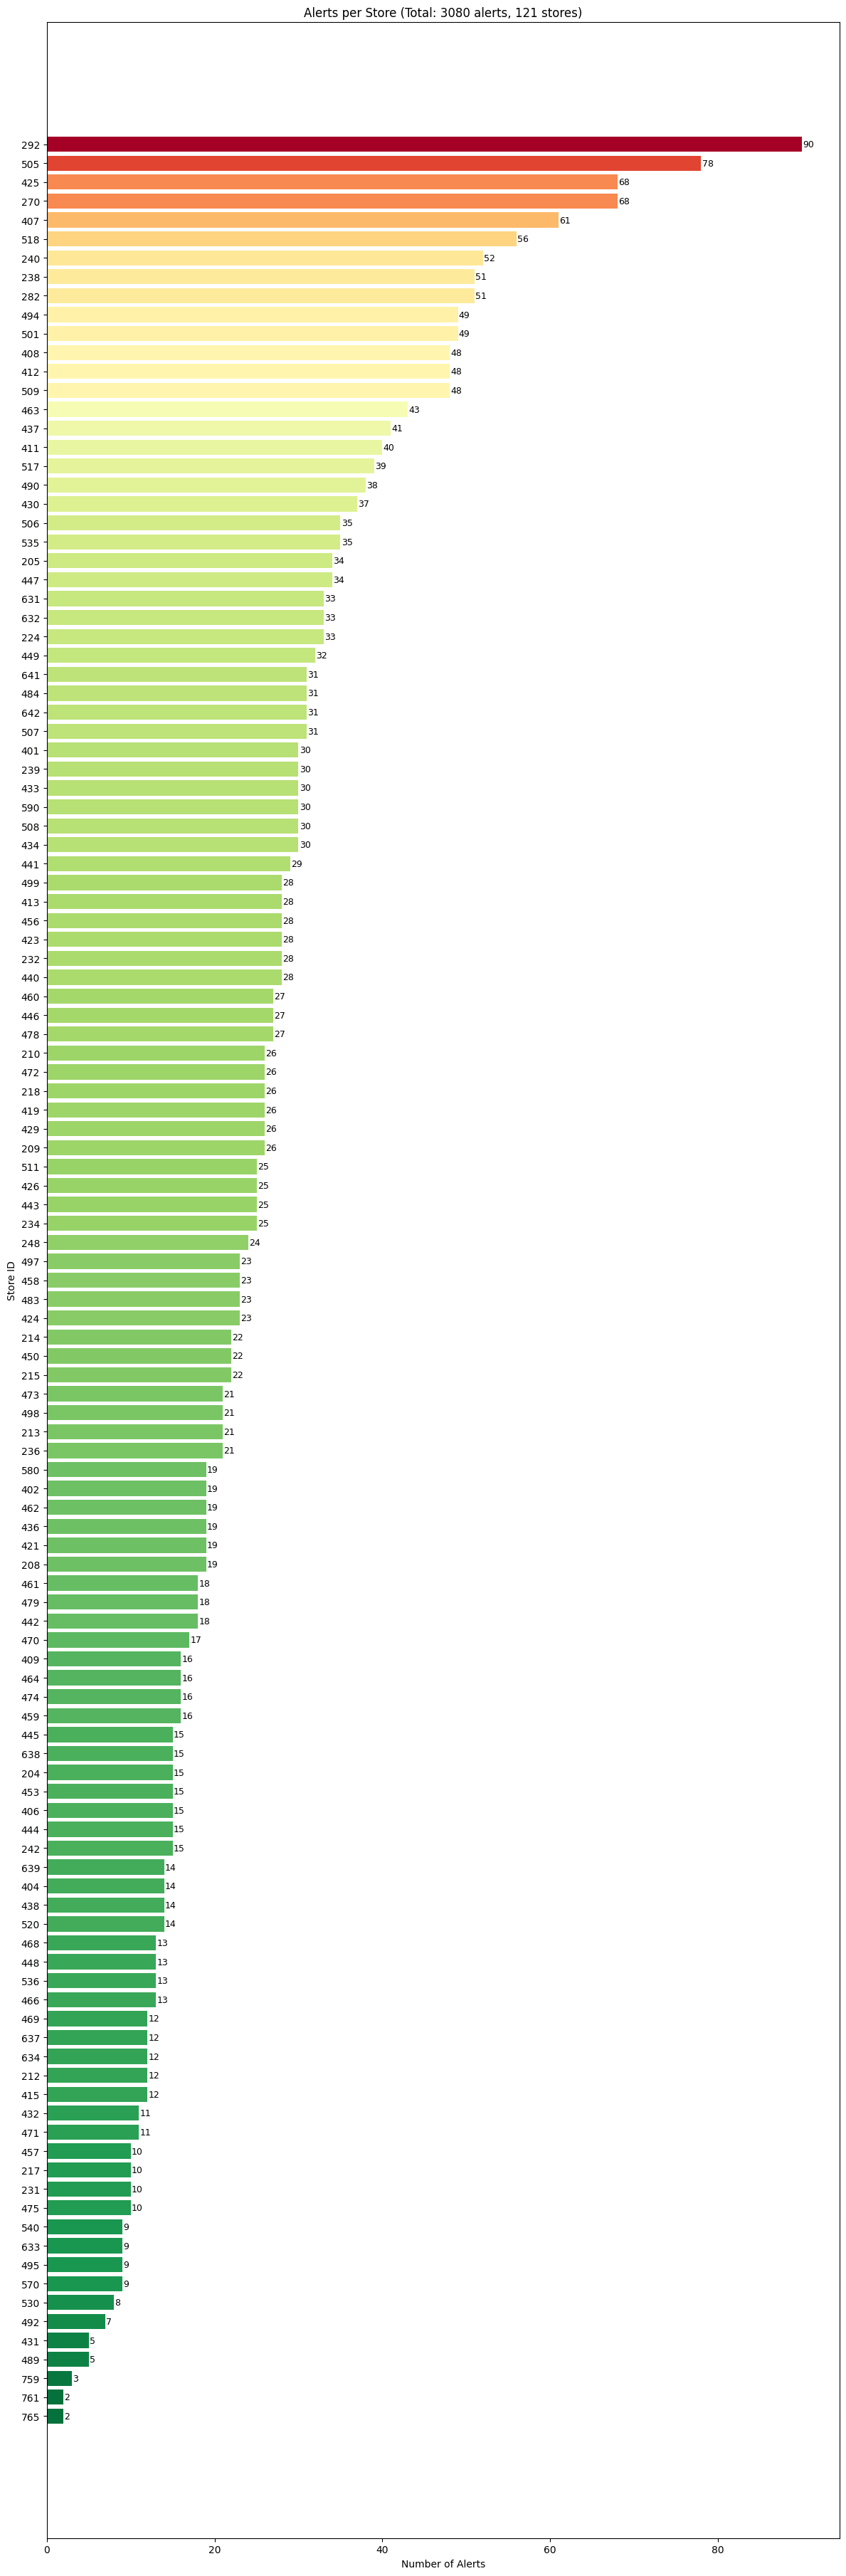


Summary:
  Mean alerts per store: 25.5
  Median: 23
  Max: 90 (Store 292)
  Stores with 1 alert: 0


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

# Count signals per store
store_counts = Counter(s['store_id'] for s in signals)

# Convert to DataFrame and sort
df_counts = pd.DataFrame([
    {'store_id': store_id, 'alert_count': count}
    for store_id, count in store_counts.most_common()
])

# Create ranked bar chart
fig, ax = plt.subplots(figsize=(12, max(6, len(df_counts) * 0.3)))
colors = plt.cm.RdYlGn_r(df_counts['alert_count'] / df_counts['alert_count'].max())

bars = ax.barh(range(len(df_counts)), df_counts['alert_count'], color=colors)
ax.set_yticks(range(len(df_counts)))
ax.set_yticklabels(df_counts['store_id'])
ax.invert_yaxis()  # Highest at top
ax.set_xlabel('Number of Alerts')
ax.set_ylabel('Store ID')
ax.set_title(f'Alerts per Store (Total: {len(signals)} alerts, {len(df_counts)} stores)')

# Add value labels on bars
for i, (bar, count) in enumerate(zip(bars, df_counts['alert_count'])):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            str(count), va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Summary stats
print(f"\nSummary:")
print(f"  Mean alerts per store: {df_counts['alert_count'].mean():.1f}")
print(f"  Median: {df_counts['alert_count'].median():.0f}")
print(f"  Max: {df_counts['alert_count'].max()} (Store {df_counts.iloc[0]['store_id']})")
print(f"  Stores with 1 alert: {(df_counts['alert_count'] == 1).sum()}")

## Stage 2 — Scoring: Assigns each signal a composite score (or raw projected_cost if composite is disabled). Signals are sorted by score; a top-N filter can be applied before enrichment.

In [8]:
import copy
from store_insight.pipeline.stages._2_score.score import score_all, apply_top_n_filter

# Build a scoring_cfg dict that merges the QC overrides with whatever is in cfg.scoring
_base_scoring = cfg.scoring.model_dump() if cfg.scoring else {}
scoring_cfg = {
    **_base_scoring,
    **(
        {
            'composite_weights': COMPOSITE_WEIGHTS,
            'cost_ceilings':     COST_CEILINGS,
            'benchmark_ceilings': BENCHMARK_CEILINGS,
            'wow_ceilings':      WOW_CEILINGS,
        }
        if COMPOSITE_WEIGHTS else {}
    ),
}

# Work on a shallow copy so re-running this cell is safe
scored = [copy.copy(s) for s in signals]

score_all(
    scored,
    this_week_start=THIS_WEEK_START,
    this_week_end=THIS_WEEK_END,
    osa=osa,
    markdown_log=markdown_log,
    markdown_sales=markdown_sales,
    score_weights=cfg.scoring.score_weights if cfg.scoring else None,
    scoring_cfg=scoring_cfg if COMPOSITE_WEIGHTS else None,
)

scored.sort(key=lambda s: s.get('score', 0), reverse=True)

print(f'{len(scored)} signals scored')
print(f'Score range: {scored[-1]["score"]:.4f} – {scored[0]["score"]:.4f}')
print(f'Top 5 by score:')
for s in scored[:5]:
    print(f'  store={s["store_id"]:>4}  type={s["signal_type"]:<22}  triggers={"+".join(s["trigger_types"]):<35}  score={s["score"]:.4f}')

[4_score] 3080 signals scored
3080 signals scored
Score range: 0.0750 – 0.9250
Top 5 by score:
  store= 218  type=WASTE                   triggers=VS_CHAIN+WOW                         score=0.9250
  store= 218  type=MARKDOWN_SELLTHROUGH    triggers=VS_CHAIN+WOW                         score=0.7361
  store= 447  type=WASTE                   triggers=VS_CHAIN+WOW                         score=0.7343
  store= 456  type=WASTE                   triggers=VS_CHAIN                             score=0.7060
  store= 535  type=WASTE                   triggers=VS_CHAIN+WOW                         score=0.7055


In [9]:
# Check what the financial_severity dimension receives
from store_insight.pipeline.stages._2_score.dimensions.financial_severity import score as fin_score

s = scored[0]  # First signal
projected_cost = s.get('score', 0)
ceiling = COST_CEILINGS.get(s['signal_type'], 5000)
print(f"signal_type: {s['signal_type']}")
print(f"projected_cost: {projected_cost}")
print(f"ceiling: {ceiling}")
print(f"financial_severity: {fin_score(s, projected_cost, ceiling)}")

signal_type: WASTE
projected_cost: 0.925
ceiling: 2000.0
financial_severity: 0.0004625


In [10]:
### Inspect — Composite Dimension Breakdown (top 20 signals)
# Shows each dimension's raw score alongside the final composite score.
# Only meaningful when COMPOSITE_WEIGHTS is set.

from store_insight.pipeline.stages._2_score.dimensions import (
    financial_severity, vs_control_benchmark, vs_historical_benchmark,
    thematic, historical_recency, special_cases,
)
from store_insight.pipeline.stages._2_score import composite as _composite

if not COMPOSITE_WEIGHTS:
    print('Composite scoring is disabled — set COMPOSITE_WEIGHTS in Cell 1 to see dimension breakdown.')
else:
    rows = []
    for s in scored[:20]:
        stype        = s.get('signal_type', '')
        cost         = s.get('projected_cost', 0)   # score already IS composite; reconstruct projected_cost
        # Re-derive projected_cost from composite formula (approx — purely for display)
        fs  = financial_severity.score(s, cost, COST_CEILINGS.get(stype, 0))
        vcb = vs_control_benchmark.score(s, BENCHMARK_CEILINGS.get(stype, 0))
        vhb = vs_historical_benchmark.score(s, WOW_CEILINGS.get(stype, 0))
        th  = thematic.score(s)
        hr  = historical_recency.score(s)
        sc  = special_cases.score(s)
        rows.append({
            'store': s['store_id'],
            'type':  stype,
            'triggers': '+'.join(s.get('trigger_types', [])),
            'fin_sev':  round(fs,  3),
            'vs_ctrl':  round(vcb, 3),
            'vs_hist':  round(vhb, 3),
            'thematic': round(th,  3),
            'recency':  round(hr,  3),
            'special':  round(sc,  3),
            'composite': round(s['score'], 4),
        })

    # Pretty-print as a table
    hdr = f"{'store':>5}  {'type':<22}  {'triggers':<30}  {'fin':>5}  {'ctrl':>5}  {'hist':>5}  {'them':>5}  {'rec':>5}  {'spec':>5}  {'score':>7}"
    print(hdr)
    print('-' * len(hdr))
    for r in rows:
        print(
            f"{r['store']:>5}  {r['type']:<22}  {r['triggers']:<30}  "
            f"{r['fin_sev']:>5.3f}  {r['vs_ctrl']:>5.3f}  {r['vs_hist']:>5.3f}  "
            f"{r['thematic']:>5.3f}  {r['recency']:>5.3f}  {r['special']:>5.3f}  "
            f"{r['composite']:>7.4f}"
        )

store  type                    triggers                          fin   ctrl   hist   them    rec   spec    score
----------------------------------------------------------------------------------------------------------------
  218  WASTE                   VS_CHAIN+WOW                    1.000  1.000  1.000  0.500  0.500  0.500   0.9250
  218  MARKDOWN_SELLTHROUGH    VS_CHAIN+WOW                    1.000  0.433  0.527  0.500  0.500  0.500   0.7361
  447  WASTE                   VS_CHAIN+WOW                    0.619  1.000  1.000  0.500  0.500  0.500   0.7343
  456  WASTE                   VS_CHAIN                        0.762  1.000  0.000  0.500  0.500  0.500   0.7060
  535  WASTE                   VS_CHAIN+WOW                    0.561  1.000  1.000  0.500  0.500  0.500   0.7055
  240  WASTE                   VS_CHAIN                        0.822  0.761  0.000  0.500  0.500  0.500   0.6765
  642  WASTE                   VS_CHAIN+WOW                    0.393  1.000  0.884  0.500  0.500

In [11]:
# Check if wow_change_pp exists for WASTE signals
waste_signals = [s for s in scored if s.get('signal_type') == 'WASTE']
print("Store 218 WASTE fields:", [k for k in waste_signals[0].keys() if 'wow' in k.lower()])
print("wow_change_pp value:", waste_signals[0].get('wow_change_pp'))

Store 218 WASTE fields: ['wow_change_pp']
wow_change_pp value: 73.38


## Stage 3 — Fact Gathering: Enriches scored signals with department breakdowns, drilldowns, day-of-week, chain drift, history, projections.

In [12]:
from store_insight.pipeline.stages._3_facts.facts import enrich_signals

enriched = enrich_signals(
    scored,
    osa,
    last_week_start=LAST_WEEK_START,
    last_week_end=LAST_WEEK_END,
    this_week_start=THIS_WEEK_START,
    this_week_end=THIS_WEEK_END,
    lookback_start=LOOKBACK_START,
    section='ITEM_HIERARCHY_2',
    projection_weeks=PROJECTION_WEEKS,
    drilldown_top_n=DRILLDOWN_TOP_N,
    feedback=feedback,
    markdown_log=markdown_log,
    markdown_sales=markdown_sales,
    wastage=wastage,
    item_hierarchy=wmd_item_hierarchy,
    cfg=cfg,
)

print(f'{len(enriched)} signals enriched')

[2_facts] 3080 signals enriched
3080 signals enriched


In [13]:
### Inspect — one enriched signal per signal type
from collections import defaultdict

by_type = defaultdict(list)
for s in enriched:
    by_type[s['signal_type']].append(s)

for stype, sigs in sorted(by_type.items()):
    s = sigs[0]
    facts_keys = list(s.get('facts', {}).keys())
    print(f'{stype} (store={s["store_id"]}, score={s.get("score", "?"):.4f})')
    print(f'  facts keys : {facts_keys}')
    print()

COMPLIANCE (store=490, score=0.3037)
  facts keys : ['tf_by_alert_type']

MARKDOWN_OVERRIDE (store=408, score=0.4847)
  facts keys : ['override_dept_breakdown']

MARKDOWN_SELLTHROUGH (store=218, score=0.7361)
  facts keys : ['sellthrough_dept_breakdown']

MARKDOWN_SKU (store=484, score=0.0750)
  facts keys : ['sku_markdown_history']

OSA (store=270, score=0.5120)
  facts keys : ['subclass_contributors', 'subclass_changes', 'dow_pattern', 'worst_day', 'chain_last_week_osa', 'chain_this_week_osa', 'chain_drift_pp', 'repeat_item_history', 'cost_projection', 'projection_weeks']

WASTE (store=218, score=0.9250)
  facts keys : ['waste_dept_breakdown']



# Stage 4 -- Investigate

In [17]:
from store_insight.pipeline.stages._4_investigate.investigate import investigate
from store_insight.pipeline.stages._2_score.score import short_long_term_label

narratives = [investigate(sig, session=session, cfg=cfg) for sig in enriched]

REQUIRED_FIELDS = ['issue', 'explanation', 'cost_if_not_fixed', 'recommended_action']
blank_fields = [
    (enriched[i]['signal_type'], enriched[i]['store_id'], k)
    for i, nar in enumerate(narratives)
    for k in REQUIRED_FIELDS if not nar.get(k)
]

print(f'{len(narratives)} narratives generated')
if blank_fields:
    print(f'WARNING — {len(blank_fields)} blank fields:')
    for b in blank_fields[:10]:
        print(f'  type={b[0]}  store={b[1]}  missing={b[2]}')
else:
    print('All four fields populated for every narrative.')

3080 narratives generated
All four fields populated for every narrative.


In [18]:
from store_insight.pipeline.pipeline.pipeline import _build_card

by_type = {}
for sig, nar in zip(enriched, narratives):
    stype = sig['signal_type']
    if stype not in by_type:
        label = short_long_term_label(sig)
        card  = _build_card(sig, nar, sig['score'], cfg=cfg, label=label)
        by_type[stype] = card

for stype, card in sorted(by_type.items()):
    print(f'═══ {stype} ═══')
    for k, v in card.items():
        if k in ('signal_json', 'facts_json', 'llm_prompt'):
            continue
        print(f'  {k:<22}: {v}')
    print()

═══ COMPLIANCE ═══
  alert_type            : TICK_AND_FLICK
  store_id              : 490
  section               : None
  type                  : Compliance
  trigger_types         : ['TICK_AND_FLICK']
  short_long_term_label : Structural
  issue                 : Thorpe St Andrew: tick-and-flick compliance declining
  explanation           : 52 of 86 alerts worked this week were tick-and-flick (60.5%).
Tick-and-flick rate rose +16.6pp week-on-week (last week: 43.9%, 36 of 82 alerts).
Store tick-and-flick rate is 28.0pp above the chain average of 32.4%.
  cost_if_not_fixed     : Unresolved alerts mean availability issues go unaddressed, increasing risk of lost sales across affected departments.
  recommended_action    : Review alert working practice with colleagues at Thorpe St Andrew. Ensure alerts are being genuinely investigated before being closed — spot-check the alert types above. Consider a coaching session with the store manager on accurate alert feedback.
  sort_value        

# Stage 4b -- LLM investigation

In [19]:
from store_insight.pipeline.stages._4_investigate import cortex

# Get top 10 signals by score
top_10 = sorted(enriched, key=lambda s: s.get('score', 0), reverse=True)[:10]

# Force cortex engine for all signal types
class CortexOverride:
    def __init__(self, sig_type):
        self.engine = 'cortex'
        self.skill_file = f'{sig_type.lower()}_skill.md'

# Generate narratives using cortex
print(f'Running Cortex LLM investigation on top {len(top_10)} signals...\n')
cortex_narratives = []
for sig in top_10:
    nar = cortex.generate(sig, session)
    cortex_narratives.append(nar)
    print(f"Store {sig['store_id']} {sig['signal_type']} (score={sig.get('score',0):.4f})")
    print(f"  Issue: {nar.get('issue', 'N/A')[:80]}...")
    print()

print(f'Cortex narratives generated for top {len(top_10)} signals.')

Running Cortex LLM investigation on top 10 signals...

Store 218 WASTE (score=0.9250)
  Issue: Straight-to-bin waste 87.8% — 59.8pp above chain average...

Store 218 MARKDOWN_SELLTHROUGH (score=0.7361)
  Issue: MARKDOWN SELL-THROUGH: 91.0% this week — 6.5pp below chain average and dropped 7...

Store 447 WASTE (score=0.7343)
  Issue: Straight-to-bin waste 83.7% — 55.7pp above chain average...

Store 456 WASTE (score=0.7060)
  Issue: STRAIGHT-TO-BIN WASTE: 52.5% rate — 24.6pp above chain average...

Store 535 WASTE (score=0.7055)
  Issue: Straight-to-bin waste 48.4% — 20.5pp above chain average...

Store 240 WASTE (score=0.6765)
  Issue: STRAIGHT-TO-BIN WASTE: 39.4% rate — 11.4pp above chain average...

Store 642 WASTE (score=0.6099)
  Issue: Straight-to-bin waste 46.7% — 18.7pp above chain average...

Store 590 WASTE (score=0.5976)
  Issue: Straight-to-bin waste 54.3% — 26.3pp above chain average...

Store 497 WASTE (score=0.5944)
  Issue: STRAIGHT-TO-BIN WASTE: 57.8% rate — 29.8pp abo

In [21]:
top_10[0]

{'signal_type': 'WASTE',
 'merge_key': ('WASTE', 218),
 'store_id': 218,
 'site_name': 'Prettygate',
 'trigger_types': ['VS_CHAIN', 'WOW'],
 'this_week_stb_rate': 87.79,
 'last_week_stb_rate': 14.41,
 'wow_change_pp': 73.38,
 'chain_stb_rate': 27.97,
 'above_chain_pp': 59.82,
 'this_week_waste_qty': 985,
 'this_week_stb_qty': None,
 'this_week_waste_value': 3024.27,
 'projected_cost': 3024.27,
 'score': 0.925,
 'facts': {'waste_dept_breakdown': [{'dept': 'Unknown',
    'waste_qty': 985,
    'waste_rate_pct': 0.0,
    'waste_value': 3024.27}]}}

In [20]:
# Display full Cortex narratives for top 10 signals
for sig, nar in zip(top_10, cortex_narratives):
    print(f"═══ {sig['signal_type']} (Store {sig['store_id']}, Score: {sig.get('score',0):.4f}) ═══")
    print(f"  Triggers : {sig.get('trigger_types', [])}")
    print(f"  Section  : {sig.get('section', 'N/A')}")
    print()
    print(f"Issue:\n{nar.get('issue', 'N/A')}")
    print()
    print(f"Explanation:\n{nar.get('explanation', 'N/A')}")
    print()
    print(f"Cost if not fixed:\n{nar.get('cost_if_not_fixed', 'N/A')}")
    print()
    print(f"Recommended action:\n{nar.get('recommended_action', 'N/A')}")
    print()
    print("─" * 80)
    print()

═══ WASTE (Store 218, Score: 0.9250) ═══
  Triggers : ['VS_CHAIN', 'WOW']
  Section  : N/A

Issue:
Straight-to-bin waste 87.8% — 59.8pp above chain average

Explanation:
985 of 985 wasted units (87.8%) went straight to bin this week. Chain average STB rate is 28.0% — this store is 59.8pp above. Last week the rate was 14.4% — up 73.4pp.

Cost if not fixed:
If left unaddressed, items worth approximately £3,024.27 per week are being discarded that could have generated revenue through markdowns.

Recommended action:
Review end-of-life processes across all departments — ensure items flagged for markdown are being actioned before they reach their waste date. Check whether the markdown algorithm is being followed and items are not being binned before markdown is applied.

────────────────────────────────────────────────────────────────────────────────

═══ MARKDOWN_SELLTHROUGH (Store 218, Score: 0.7361) ═══
  Triggers : ['VS_CHAIN', 'WOW']
  Section  : N/A

Issue:
MARKDOWN SELL-THROUGH: 91.0%